<a href="https://colab.research.google.com/github/SaharaAli16/UNT_Teaching/blob/main/DTSC_4050/Week_12_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — In-Class Activity: Simple Linear Regression

This activity follows the regression topics in the lecture slides.

## Learning goals
By the end of class, you should be able to:
- identify predictor **X** and response **Y**;
- inspect a scatter plot before fitting a model;
- calculate and interpret correlation;
- fit and interpret a simple linear regression;
- distinguish observed values, fitted values, and residuals;
- calculate MAE, MSE, and RMSE;
- use residual plots to assess a linear model;
- make predictions and recognize extrapolation;
- bootstrap a regression slope and use its 95% confidence interval to assess whether a true slope of 0 is plausible.

Complete all **YOUR TURN** sections.


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(4050)


## 2. Warm-up: Which Variable Is X and Which Is Y?

We begin with the baby example from the lesson.

| Baby | Gestational Days (X) | Birth Weight, oz (Y) |
|---|---:|---:|
| 1 | 270 | 112 |
| 2 | 278 | 118 |
| 3 | 285 | 124 |
| 4 | 292 | 126 |
| 5 | 300 | 132 |

Discuss:
1. Which variable is the predictor?
2. Which variable is the response?



In [2]:
babies = pd.DataFrame({
    "gestational_days": [270, 278, 285, 292, 300],
    "birth_weight_oz": [112, 118, 124, 126, 132]
})
babies


,gestational_days,birth_weight_oz
0,270,112
1,278,118
2,285,124
3,292,126
4,300,132


## 3. Look Before You Infer

Start with a scatter plot. Look for a roughly linear pattern, unusual observations, and curvature.


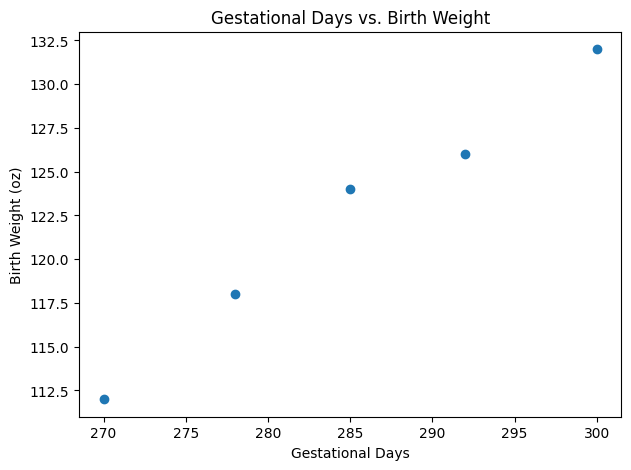

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(babies["gestational_days"], babies["birth_weight_oz"])
plt.xlabel("Gestational Days")
plt.ylabel("Birth Weight (oz)")
plt.title("Gestational Days vs. Birth Weight")
plt.show()


### YOUR TURN 1
**A.** Is the association positive, negative, or approximately zero?  
**Answer:**

**B.** Does a straight-line model appear reasonable? Explain briefly.  
**Answer:**


## 4. Correlation

The correlation coefficient **r** summarizes the direction and strength of a **linear** association.

- $r > 0$: positive linear association
- $r < 0$: negative linear association
- $r$ near 0: weak or no linear association
- correlation has no units
- correlation describes association, not causation


In [4]:
r = babies["gestational_days"].corr(babies["birth_weight_oz"])
print(f"Correlation r = {r:.3f}")


Correlation r = 0.992


## 5. Fit a Simple Linear Regression

The fitted equation is

$$\hat{y} = b_0 + b_1x$$

where $b_0$ is the sample intercept and $b_1$ is the sample slope.


In [5]:
X = babies[["gestational_days"]]
y = babies["birth_weight_oz"]

model = LinearRegression()
model.fit(X, y)

intercept = model.intercept_
slope = model.coef_[0]

print(f"Intercept = {intercept:.3f}")
print(f"Slope = {slope:.3f} oz/day")
print(f"Equation: predicted weight = {intercept:.3f} + {slope:.3f} × gestational days")


Intercept = -62.746
Slope = 0.650 oz/day
Equation: predicted weight = -62.746 + 0.650 × gestational days


### YOUR TURN 2 — Interpret the Model
**A. Slope:** For each additional gestational day, fitted birth weight changes by approximately ______ ounces.

**B. Intercept:** What does the intercept mathematically represent?

**Answer:**


## 6. Visualize the Fitted Regression Line

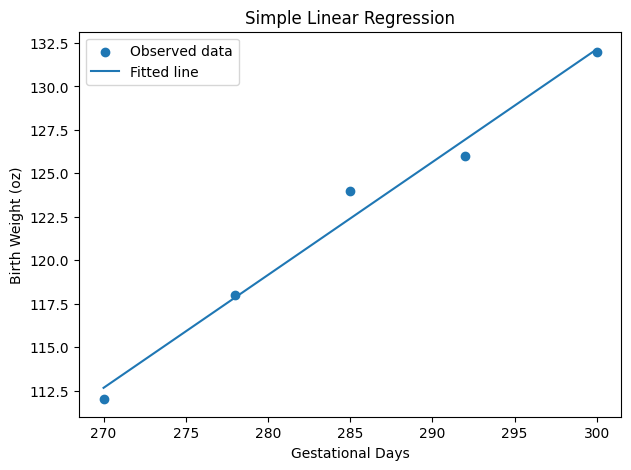

In [6]:
x_line = np.linspace(babies["gestational_days"].min(),
                     babies["gestational_days"].max(), 100)
line_df = pd.DataFrame({"gestational_days": x_line})
y_line = model.predict(line_df)

plt.figure(figsize=(7, 5))
plt.scatter(babies["gestational_days"], babies["birth_weight_oz"], label="Observed data")
plt.plot(x_line, y_line, label="Fitted line")
plt.xlabel("Gestational Days")
plt.ylabel("Birth Weight (oz)")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()


## 7. Observed Values, Fitted Values, and Residuals

$$\text{Residual} = y - \hat{y}$$

A positive residual means the observation is above the fitted line. A negative residual means it is below the line.


In [7]:
babies["predicted_weight"] = model.predict(X)
babies["residual"] = babies["birth_weight_oz"] - babies["predicted_weight"]
babies.round(2)


,gestational_days,birth_weight_oz,predicted_weight,residual
0,270,112,112.66,-0.66
1,278,118,117.85,0.15
2,285,124,122.40,1.60
3,292,126,126.95,-0.95
4,300,132,132.14,-0.14


### YOUR TURN 3
1. Which baby has the largest positive residual?
2. Which has the largest negative residual?


**Answer:**


## 8. Prediction Error Metrics

- **MAE:** average of $|observed-predicted|$
- **MSE:** average squared residual
- **RMSE:** square root of MSE; same units as Y


In [8]:
mae = mean_absolute_error(y, babies["predicted_weight"])
mse = mean_squared_error(y, babies["predicted_weight"])
rmse = np.sqrt(mse)

print(f"MAE  = {mae:.3f} oz")
print(f"MSE  = {mse:.3f} squared oz")
print(f"RMSE = {rmse:.3f} oz")


MAE  = 0.699 oz
MSE  = 0.786 squared oz
RMSE = 0.887 oz


### YOUR TURN 4
Which error metrics above are expressed in the same units as birth weight?

**Answer:**


## 9. Examine the Residual Plot

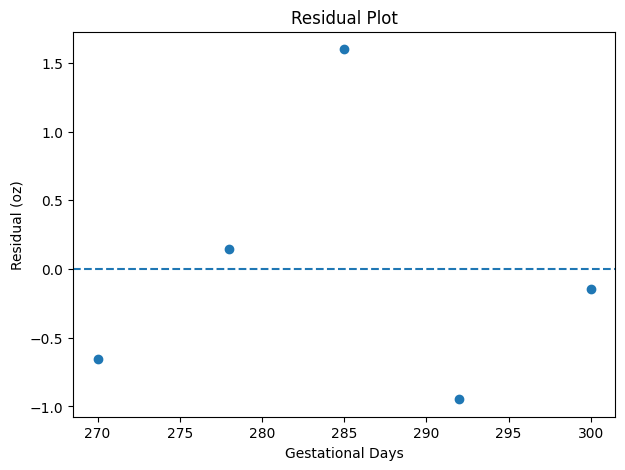

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(babies["gestational_days"], babies["residual"])
plt.axhline(0, linestyle="--")
plt.xlabel("Gestational Days")
plt.ylabel("Residual (oz)")
plt.title("Residual Plot")
plt.show()


## 10. Fitted Values and Prediction

A fitted value is the Y-coordinate of the fitted line for a chosen X value.


In [10]:
new_x = pd.DataFrame({"gestational_days": [300]})
prediction = model.predict(new_x)[0]
print(f"Predicted birth weight at 300 days = {prediction:.2f} oz")


Predicted birth weight at 300 days = 132.14 oz


### YOUR TURN 5
Modify the code below to predict birth weight at **290 gestational days**.

In [11]:
# YOUR CODE HERE
new_days = 290

# Hint:
# new_value = pd.DataFrame({"gestational_days": [new_days]})
# ...


## 11. Extrapolation

The observed X values range from 270 to 300 days. A prediction far outside that range is **extrapolation**.


In [12]:
outside_x = pd.DataFrame({"gestational_days": [400]})
outside_prediction = model.predict(outside_x)[0]
print(f"Mathematical model prediction at 400 days = {outside_prediction:.2f} oz")


Mathematical model prediction at 400 days = 197.11 oz


# Part II — Inference for the Regression Slope

The sample line is an estimate of an unknown population relationship. If we had collected a different random sample, our estimated slope would usually differ.

We will use bootstrap resampling to examine this uncertainty.


## 12. A Larger Synthetic Sample

In [13]:
n = 80
gest_days = np.random.normal(280, 10, n)
birth_weight = 0.55 * gest_days - 35 + np.random.normal(0, 8, n)

sample = pd.DataFrame({
    "gestational_days": gest_days,
    "birth_weight_oz": birth_weight
})

sample.head()


,gestational_days,birth_weight_oz
0,280.682042,126.018086
1,291.815962,117.964476
2,294.502107,128.001324
3,274.770652,125.387116
4,292.586150,100.849022


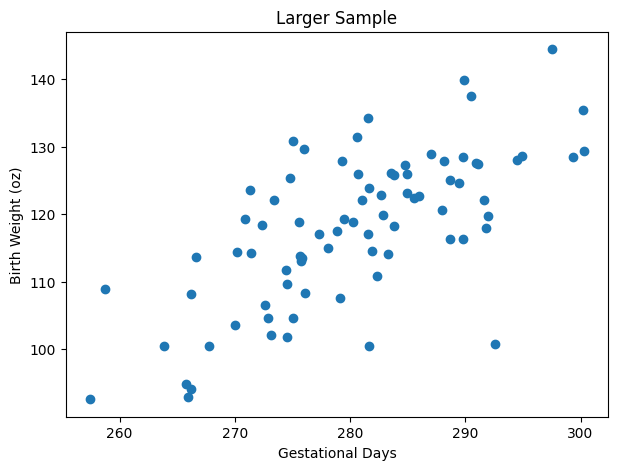

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(sample["gestational_days"], sample["birth_weight_oz"])
plt.xlabel("Gestational Days")
plt.ylabel("Birth Weight (oz)")
plt.title("Larger Sample")
plt.show()


## 13. Estimate the Sample Slope

In [15]:
sample_model = LinearRegression()
sample_model.fit(sample[["gestational_days"]], sample["birth_weight_oz"])

observed_slope = sample_model.coef_[0]
print(f"Observed sample slope = {observed_slope:.3f} oz/day")


Observed sample slope = 0.805 oz/day


## 14. Bootstrap the Slope

Each bootstrap repetition:
1. resamples rows **with replacement**;
2. fits a regression line;
3. saves the slope.


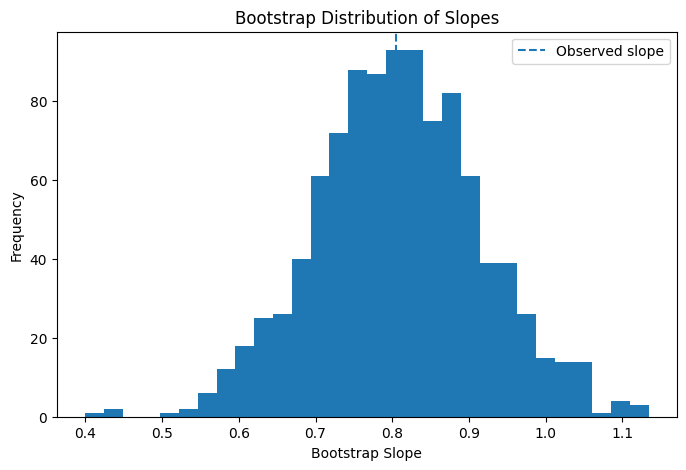

In [16]:
bootstrap_slopes = []

for i in range(1000):
    boot = sample.sample(n=len(sample), replace=True)
    boot_model = LinearRegression()
    boot_model.fit(boot[["gestational_days"]], boot["birth_weight_oz"])
    bootstrap_slopes.append(boot_model.coef_[0])

bootstrap_slopes = np.array(bootstrap_slopes)

plt.figure(figsize=(8, 5))
plt.hist(bootstrap_slopes, bins=30)
plt.axvline(observed_slope, linestyle="--", label="Observed slope")
plt.xlabel("Bootstrap Slope")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of Slopes")
plt.legend()
plt.show()


## 15. Construct an Approximate 95% Bootstrap Confidence Interval

In [17]:
lower, upper = np.percentile(bootstrap_slopes, [2.5, 97.5])

print(f"Observed slope = {observed_slope:.3f}")
print(f"Approximate 95% bootstrap CI = ({lower:.3f}, {upper:.3f})")


Observed slope = 0.805
Approximate 95% bootstrap CI = (0.597, 1.026)


# Part III — When a Straight Line Is Not Enough

A correlation near zero does not necessarily mean that two variables have no relationship. The relationship may simply be non-linear.


Correlation = 0.016


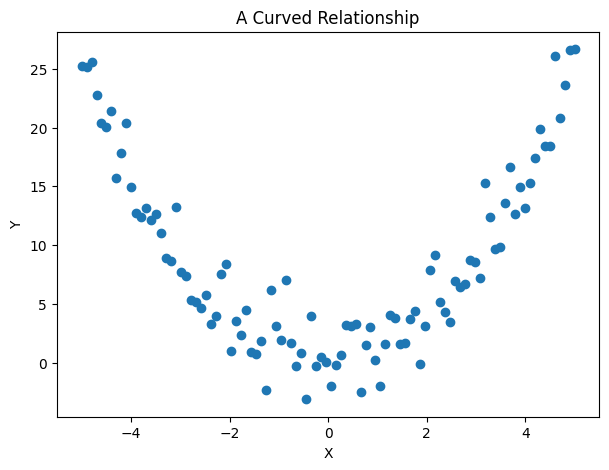

In [18]:
x_curve = np.linspace(-5, 5, 100)
y_curve = x_curve**2 + np.random.normal(0, 2, 100)
curved = pd.DataFrame({"X": x_curve, "Y": y_curve})

print(f"Correlation = {curved['X'].corr(curved['Y']):.3f}")

plt.figure(figsize=(7, 5))
plt.scatter(curved["X"], curved["Y"])
plt.xlabel("X")
plt.ylabel("Y")
plt.title("A Curved Relationship")
plt.show()


### YOUR TURN 6
1. Is there a visible relationship between X and Y?
2. Would one straight line summarize it well?


**Answer:**
